# EDA y Normalización
Fase 2 del plan de dataset de prueba ML.

**Fuentes:**
- `store_item_demand.csv` — Store Item Demand Forecasting (Kaggle)
- `logistics_warehouse.csv` — Logistics Warehouse Dataset (Kaggle)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import hashlib, json, datetime
from pathlib import Path

sns.set_theme(style='whitegrid')
RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')
PROCESSED.mkdir(exist_ok=True)

## 1. Carga y registro de hashes

In [2]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(65536), b''):
            h.update(chunk)
    return h.hexdigest()

demand_path = RAW / 'stored_item_demand.csv'
logistics_path = RAW / 'logistics_warehouse.csv'

meta = json.loads((RAW / 'metadata.json').read_text())
meta['sources'][0]['sha256'] = sha256(demand_path)
meta['sources'][0]['downloaded_at'] = str(datetime.date.today())
meta['sources'][1]['sha256'] = sha256(logistics_path)
meta['sources'][1]['downloaded_at'] = str(datetime.date.today())
(RAW / 'metadata.json').write_text(json.dumps(meta, indent=2))
print('Hashes registrados en metadata.json')

Hashes registrados en metadata.json


In [3]:
demand = pd.read_csv(demand_path, parse_dates=['date'])
logistics = pd.read_csv(logistics_path)
print('Demanda:', demand.shape)
print('Logística:', logistics.shape)
display(demand.head(3))
display(logistics.head(3))

Demanda: (913000, 4)
Logística: (3204, 23)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14


,item_id,category,stock_level,reorder_point,reorder_frequency_days,lead_time_days,daily_demand,demand_std_dev,item_popularity_score,storage_location_id,...,unit_price,holding_cost_per_unit_day,stockout_count_last_month,order_fulfillment_rate,total_orders_last_month,turnover_ratio,layout_efficiency_score,last_restock_date,forecasted_demand_next_7d,KPI_score
0,ITM10000,Pharma,283,21,4,4,49.85,1.56,0.43,L82,...,117.80,1.14,0,0.80,700,3.33,0.33,2024-02-17,184.37,0.556
1,ITM10001,Automotive,301,52,9,6,23.34,2.55,0.69,L15,...,178.80,1.09,3,0.79,736,10.36,0.98,2024-10-01,221.94,0.723
2,ITM10002,Groceries,132,60,11,8,37.69,3.15,0.62,L4,...,54.05,0.95,7,0.75,814,14.32,0.87,2024-04-07,53.85,0.680


## 2. EDA — Dataset de demanda

In [4]:
print('Rango de fechas:', demand['date'].min(), '→', demand['date'].max())
print('Tiendas:', demand['store'].nunique())
print('Items:', demand['item'].nunique())
print('Nulos:\n', demand.isnull().sum())
print('\nEstadísticas de sales:')
display(demand['sales'].describe())

Rango de fechas: 2013-01-01 00:00:00 → 2017-12-31 00:00:00
Tiendas: 10
Items: 50
Nulos:
 date     0
store    0
item     0
sales    0
dtype: int64

Estadísticas de sales:


count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

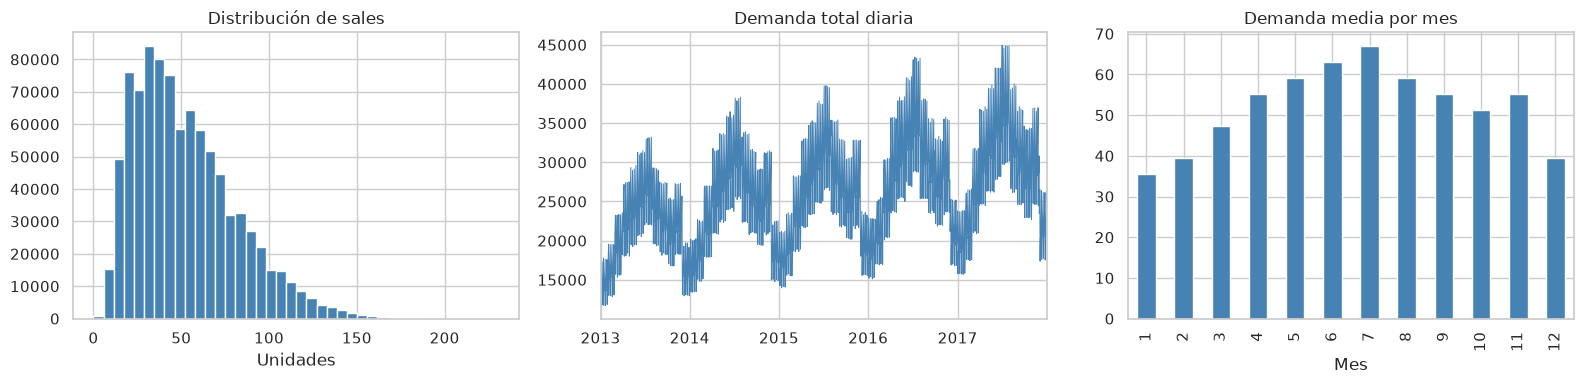

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

demand['sales'].hist(bins=40, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de sales')
axes[0].set_xlabel('Unidades')

demand.groupby('date')['sales'].sum().plot(ax=axes[1], color='steelblue', linewidth=0.7)
axes[1].set_title('Demanda total diaria')
axes[1].set_xlabel('')

demand.groupby(demand['date'].dt.month)['sales'].mean().plot(kind='bar', ax=axes[2], color='steelblue')
axes[2].set_title('Demanda media por mes')
axes[2].set_xlabel('Mes')

plt.tight_layout()
plt.savefig('../data/processed/eda_demanda.png', dpi=120)
plt.show()

## 3. EDA — Dataset de logística

In [6]:
print('Nulos:\n', logistics.isnull().sum())
print('\nCategorías:')
display(logistics['category'].value_counts())
print('\nEstadísticas clave:')
display(logistics[['daily_demand','demand_std_dev','reorder_point','stock_level','lead_time_days']].describe())

Nulos:
 item_id                      0
category                     0
stock_level                  0
reorder_point                0
reorder_frequency_days       0
lead_time_days               0
daily_demand                 0
demand_std_dev               0
item_popularity_score        0
storage_location_id          0
zone                         0
picking_time_seconds         0
handling_cost_per_unit       0
unit_price                   0
holding_cost_per_unit_day    0
stockout_count_last_month    0
order_fulfillment_rate       0
total_orders_last_month      0
turnover_ratio               0
layout_efficiency_score      0
last_restock_date            0
forecasted_demand_next_7d    0
KPI_score                    0
dtype: int64

Categorías:


category
Pharma         660
Automotive     658
Electronics    651
Groceries      618
Apparel        617
Name: count, dtype: int64


Estadísticas clave:


,daily_demand,demand_std_dev,reorder_point,stock_level,lead_time_days
count,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000
mean,25.435868,5.260078,54.759363,263.491573,5.578340
std,14.038861,2.725639,26.053354,138.568360,2.292486
min,1.010000,0.500000,10.000000,20.000000,2.000000
25%,13.535000,2.917500,32.000000,144.000000,4.000000
50%,25.405000,5.235000,55.000000,264.000000,6.000000
75%,37.412500,7.542500,78.000000,386.000000,8.000000
max,49.980000,10.000000,99.000000,499.000000,9.000000


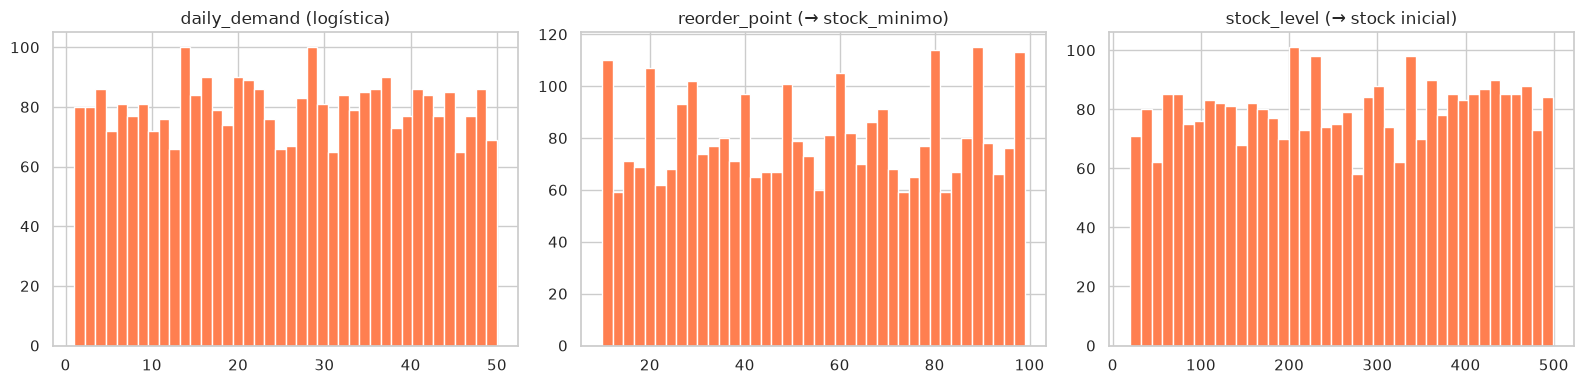

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

logistics['daily_demand'].hist(bins=40, ax=axes[0], color='coral', edgecolor='white')
axes[0].set_title('daily_demand (logística)')

logistics['reorder_point'].hist(bins=40, ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('reorder_point (→ stock_minimo)')

logistics['stock_level'].hist(bins=40, ax=axes[2], color='coral', edgecolor='white')
axes[2].set_title('stock_level (→ stock inicial)')

plt.tight_layout()
plt.savefig('../data/processed/eda_logistica.png', dpi=120)
plt.show()

## 4. Normalización y construcción de product_id

In [8]:
# Renombrar columnas de demanda
demand = demand.rename(columns={'sales': 'quantity'})
demand['product_id'] = demand['store'].astype(str) + '_' + demand['item'].astype(str)

# Mapping item → categoría (10 items por categoría, 50 items totales)
CATEGORY_MAP = {
    **{i: 'Groceries'   for i in range(1, 11)},
    **{i: 'Electronics' for i in range(11, 21)},
    **{i: 'Apparel'     for i in range(21, 31)},
    **{i: 'Automotive'  for i in range(31, 41)},
    **{i: 'Pharma'      for i in range(41, 51)},
}
demand['category'] = demand['item'].map(CATEGORY_MAP)

print('Productos únicos:', demand['product_id'].nunique())
print('Categorías asignadas:')
display(demand.groupby('category')['product_id'].nunique())

Productos únicos: 500
Categorías asignadas:


category
Apparel        100
Automotive     100
Electronics    100
Groceries      100
Pharma         100
Name: product_id, dtype: int64

## 5. Demanda media y desviación por producto

In [9]:
product_stats = (
    demand.groupby(['product_id', 'category'])['quantity']
    .agg(mean_daily_demand='mean', std_daily_demand='std', n_events='count', span_days=lambda x: (demand.loc[x.index, 'date'].max() - demand.loc[x.index, 'date'].min()).days)
    .reset_index()
)

# Filtro de elegibilidad (≥ 10 eventos y ≥ 56 días)
eligible = product_stats[(product_stats['n_events'] >= 10) & (product_stats['span_days'] >= 56)]
print(f'Productos elegibles para entrenamiento: {len(eligible)} / {len(product_stats)}')
display(product_stats.describe())

Productos elegibles para entrenamiento: 500 / 500


,mean_daily_demand,std_daily_demand,n_events,span_days
count,500.000000,500.000000,500.0,500.0
mean,52.250287,14.701935,1826.0,1825.0
std,24.062536,5.976603,0.0,0.0
min,12.733844,4.731280,1826.0,1825.0
25%,30.964266,9.449078,1826.0,1825.0
50%,50.030942,14.142238,1826.0,1825.0
75%,69.348987,18.857686,1826.0,1825.0
max,112.638007,29.676051,1826.0,1825.0


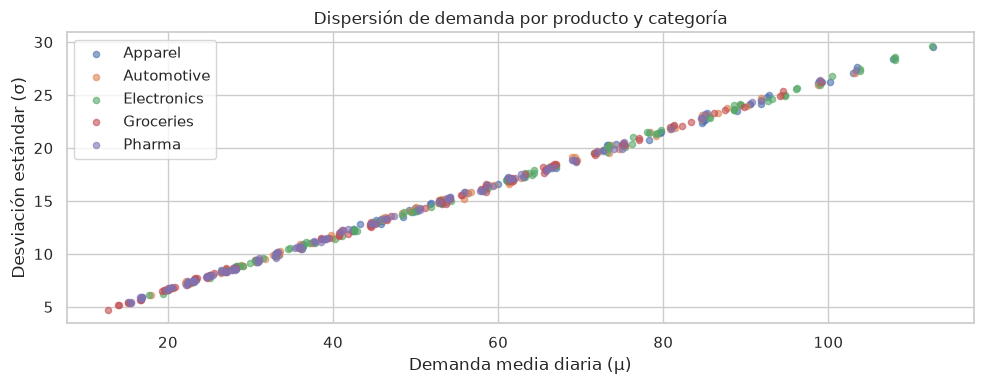

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for cat, grp in product_stats.groupby('category'):
    ax.scatter(grp['mean_daily_demand'], grp['std_daily_demand'], label=cat, alpha=0.6, s=20)
ax.set_xlabel('Demanda media diaria (μ)')
ax.set_ylabel('Desviación estándar (σ)')
ax.set_title('Dispersión de demanda por producto y categoría')
ax.legend()
plt.tight_layout()
plt.savefig('../data/processed/eda_scatter_productos.png', dpi=120)
plt.show()

## 6. Guardar artefactos normalizados

In [11]:
# Guardar demanda normalizada
demand[['date','product_id','store','item','quantity','category']].to_csv(
    PROCESSED / 'demand_normalized.csv', index=False
)

# Guardar estadísticas por producto
product_stats.to_csv(PROCESSED / 'product_stats.csv', index=False)

# Guardar logística renombrada
logistics_norm = logistics[['item_id','category','stock_level','reorder_point',
                             'lead_time_days','daily_demand','demand_std_dev']].copy()
logistics_norm.to_csv(PROCESSED / 'logistics_normalized.csv', index=False)

print('Archivos guardados en data/processed/:')
for f in sorted(PROCESSED.iterdir()):
    print(f'  {f.name} ({f.stat().st_size / 1024:.1f} KB)')

Archivos guardados en data/processed/:
  demand_normalized.csv (29873.3 KB)
  eda_demanda.png (104.9 KB)
  eda_logistica.png (43.7 KB)
  eda_scatter_productos.png (73.0 KB)
  logistics_normalized.csv (119.2 KB)
  product_stats.csv (29.9 KB)


## Resumen
| Dataset | Filas | Productos | Rango |
|---|---|---|---|
| Demanda | 913k | 500 (10 tiendas × 50 items) | 2013–2017 |
| Logística | 3204 | 3204 | — |

**Próximo paso:** `scripts/cross_reference.py` — matching estadístico para asignar `stock_minimo` y `lead_time_days` a cada producto.